In [1]:
from pathlib import Path
import pandas as pd

# Pasta principal do projeto
PROJECT_DIR = Path.cwd().parent

# Pasta contendo os arquivos originais
DATA_DIR = PROJECT_DIR / "data" / "raw" / "inca3"

# Arquivos INCA 3
files = {
    "individus": "description-indiv.csv",
    "consommations": "conso-compo-alim-vf-mad-datagouv2021.csv",
    "apports": "apports-nut-alim.csv",
    "nomenclature": "nomenclature-vf-mad-datagouv2021.csv"
}

# Verificar se os arquivos existem
for name, filename in files.items():
    path = DATA_DIR / filename
    print(f"{name}: {'OK' if path.exists() else 'NON TROUVÉ'}")

individus: OK
consommations: OK
apports: OK
nomenclature: OK


In [2]:
for name, filename in files.items():
    path = DATA_DIR / filename

    print(f"\n--- {name.upper()} ---")

    with open(path, "rb") as f:
        for _ in range(2):
            print(f.readline()[:250])


--- INDIVIDUS ---
b'\xef\xbb\xbfNOMEN;NOIND;ech;enf_allaite;pop1;pop2;pop3;pond_indiv_adu_pop1;pond_indiv_enf_pop1;pond_indiv_adu_pop2;pond_indiv_enf_pop2;pond_indiv_adu_pop3;pond_indiv_enf_pop3;pond_men_pop1;pond_men_pop2;zae;strate;fpc1;fpc2;fpc3;saison_pop1;saison_pop2;saison'
b'1101001;110100101;1;;1;1;1;11415.49801032071;;18553.73426347147;;20743.857;;397.3782009874678;561.623547096264;Z01091;6;.038265307;.16611074;.33333334;1;1;1;9;6;1;1;7;;;7;1;3;2;;;8;4;;2;0;1;2;2;2;7;1;;2;1;1;2;2;2;12;3;4;3;1;1;0;;168;;168;51.6;;51.599'

--- CONSOMMATIONS ---
b'\xef\xbb\xbfPOPULATION;NOIND;NUM_LIGNE;R24_num;R24_nombre;R24_pond;occ_hdeb;occ_type;occ_lieu;occ_alim_libelle;occ_alim_num;occ_alim_num_seq;gpe_INCA3;aliment_code_INCA3;aliment_libelle_INCA3;aliment_code_FX;aliment_libelle_FX;qte_conso;qte_conso_pond;facette'
b'Pop3;110100101;3;1;3;1;11:00;4;1;eau;1;1;30;1504;eau (du robinet);A03DL;Tap water;147.5;147.5;999;non renseign\xc3\xa9;999;non renseign\xc3\xa9;999;non renseign\xc3\xa9;999;non


## Chargement des données INCA 3

Cette étape consiste à importer les quatre fichiers CSV de l'enquête INCA 3 à l'aide de la bibliothèque Pandas.

Les données sont chargées sous forme de DataFrames afin de faciliter leur exploration, leur nettoyage et leur analyse.

Pour chaque fichier, nous vérifions le nombre de lignes et de colonnes.
  

In [3]:
# Dictionnaire destiné à stocker les DataFrames
dataframes = {}

# Chargement des quatre fichiers CSV
for name, filename in files.items():

    # Construction du chemin vers le fichier
    path = DATA_DIR / filename

    print(f"Chargement de {name}...")

    # Lecture du fichier CSV avec Pandas
    df = pd.read_csv(
        path,
        sep=";",
        encoding="utf-8-sig",
        low_memory=False
    )

    # Stockage du DataFrame dans le dictionnaire
    dataframes[name] = df

    # Affichage des dimensions du DataFrame
    print(f"  Lignes : {df.shape[0]}")
    print(f"  Colonnes : {df.shape[1]}")
    print()

Chargement de individus...
  Lignes : 5855
  Colonnes : 185

Chargement de consommations...
  Lignes : 256301
  Colonnes : 109

Chargement de apports...
  Lignes : 4114
  Colonnes : 108

Chargement de nomenclature...
  Lignes : 36734
  Colonnes : 36



## Première exploration des données

Après le chargement des fichiers, nous examinons les premières observations des tables afin de comprendre leur structure.

La méthode `head()` permet d'afficher les cinq premières lignes d'un DataFrame.

Cette exploration préliminaire nous aidera à identifier les variables pertinentes pour les analyses nutritionnelles.

In [4]:
# Affichage des cinq premières observations de la table des individus
display(dataframes["individus"].head())

# Affichage des cinq premières observations de la table des apports nutritionnels
display(dataframes["apports"].head())

,NOMEN,NOIND,ech,enf_allaite,pop1,pop2,pop3,pond_indiv_adu_pop1,pond_indiv_enf_pop1,pond_indiv_adu_pop2,...,fume_age_debut_nsp,fume_age_arret,fume_age_arret_nsp,bmr_kcal,sousest0,surest0,sousest1,sousest3,sousext,surext
0,1101001,110100101,1,NaN,1,1,1,11415.498010,NaN,18553.734263,...,NaN,NaN,NaN,1378.0930,0.0,0.0,0.0,NaN,0.0,0.0
1,1101007,110100701,1,NaN,1,1,1,4644.245013,NaN,4656.461407,...,NaN,NaN,NaN,1352.7802,1.0,0.0,1.0,NaN,0.0,0.0
2,1101008,110100801,1,NaN,1,1,1,6016.879562,NaN,6307.757457,...,NaN,33.0,NaN,1630.9735,0.0,0.0,0.0,NaN,0.0,0.0
3,1101012,110101201,1,NaN,1,1,1,1782.445803,NaN,2041.062541,...,NaN,NaN,NaN,1749.4603,0.0,0.0,0.0,NaN,0.0,0.0
4,1101014,110101401,1,NaN,1,1,1,2359.105604,NaN,2455.423813,...,NaN,NaN,NaN,1090.1117,0.0,0.0,0.0,NaN,0.0,0.0


,POPULATION,NOIND,nutriment1,nutriment2,nutriment3,nutriment4,nutriment5,nutriment6,nutriment7,nutriment8,...,contrib45,contrib46,contrib47,contrib48,contrib49,contrib50,contrib51,contrib52,contrib53,contrib54
0,Pop3,110100101,2077.7625,2077.2795,83.054970,287.46045,145.453580,118.051110,0.272250,16.439404,...,0.074628,0.946185,0.345410,0.110520,16.502401,0.215986,8.642483,0.106113,0.258121,1.267153
1,Pop3,110100701,1123.7395,1122.6108,42.008881,141.19160,87.729454,40.941555,1.554727,21.721514,...,0.145274,1.462126,0.317232,0.098729,30.148006,0.119924,24.783506,0.252590,0.718946,0.070505
2,Pop3,110100801,2544.5754,2543.0146,87.255280,292.85364,148.375690,123.386040,0.837265,20.448515,...,0.050513,0.944199,0.214649,0.066984,11.707060,0.131240,6.312596,0.114005,0.332603,1.175436
3,Pop3,110101201,2154.6367,1738.7144,64.621910,176.34831,108.290740,52.579441,0.252013,14.028072,...,0.230425,1.569673,0.578777,0.112707,14.442437,0.533786,10.153035,0.224728,1.051633,0.520615
4,Pop3,110101401,1229.2993,1230.0304,44.161503,134.01630,52.806332,67.524727,0.441230,12.723254,...,0.124503,0.932228,0.360054,0.078900,15.277953,0.157646,2.613579,0.183976,0.467196,1.011166


## Contrôle de qualité des données

Après le chargement des quatre tables INCA 3, nous réalisons un premier contrôle de qualité afin d'évaluer leur structure et leur cohérence.

Cette étape consiste à :

- Identifier les types des variables.
- Quantifier les valeurs manquantes.
- Détecter les lignes dupliquées.
- Vérifier l'unicité des identifiants.
- Examiner les relations entre les différentes tables.

Ces vérifications sont nécessaires avant le nettoyage des données, la construction de la base relationnelle et les analyses nutritionnelles.

In [5]:
# Analyse générale de la qualité des données

for name, df in dataframes.items():

    print(f"\n{'=' * 50}")
    print(f"TABLE : {name.upper()}")
    print(f"{'=' * 50}")

    # Dimensions de la table
    print(f"Nombre de lignes : {df.shape[0]}")
    print(f"Nombre de colonnes : {df.shape[1]}")

    # Nombre total de valeurs manquantes
    print(f"Valeurs manquantes : {df.isna().sum().sum()}")

    # Pourcentage global de valeurs manquantes
    pourcentage_na = df.isna().sum().sum() / df.size * 100
    print(f"Pourcentage de valeurs manquantes : {pourcentage_na:.2f}%")

    # Nombre de lignes entièrement dupliquées
    print(f"Lignes dupliquées : {df.duplicated().sum()}")

    # Répartition des types de variables
    print("\nTypes de variables :")
    print(df.dtypes.value_counts())


TABLE : INDIVIDUS
Nombre de lignes : 5855
Nombre de colonnes : 185
Valeurs manquantes : 494640
Pourcentage de valeurs manquantes : 45.67%
Lignes dupliquées : 0

Types de variables :
float64    144
int64       33
str          8
Name: count, dtype: int64

TABLE : CONSOMMATIONS
Nombre de lignes : 256301
Nombre de colonnes : 109
Valeurs manquantes : 385423
Pourcentage de valeurs manquantes : 1.38%
Lignes dupliquées : 0

Types de variables :
float64    59
str        30
int64      20
Name: count, dtype: int64

TABLE : APPORTS
Nombre de lignes : 4114
Nombre de colonnes : 108
Valeurs manquantes : 416
Pourcentage de valeurs manquantes : 0.09%
Lignes dupliquées : 0

Types de variables :
float64    106
str          1
int64        1
Name: count, dtype: int64

TABLE : NOMENCLATURE
Nombre de lignes : 36734
Nombre de colonnes : 36
Valeurs manquantes : 490499
Pourcentage de valeurs manquantes : 37.09%
Lignes dupliquées : 0

Types de variables :
str        18
float64    11
int64       7
Name: count, d

## Vérification des identifiants individuels

La variable `NOIND` permet d'identifier les participants de l'enquête INCA 3.

Nous vérifions le nombre d'identifiants distincts dans chaque table et examinons leur unicité.

Dans les tables de consommation alimentaire, un même individu peut apparaître plusieurs fois, car plusieurs aliments peuvent être déclarés par participant.

In [6]:
# Vérification de la variable NOIND dans les tables

for name, df in dataframes.items():

    if "NOIND" in df.columns:

        # Nombre d'identifiants distincts
        nb_individus = df["NOIND"].nunique()

        # Nombre de valeurs manquantes dans l'identifiant
        nb_manquants = df["NOIND"].isna().sum()

        # Nombre de répétitions de l'identifiant
        nb_repetitions = df["NOIND"].duplicated().sum()

        print(f"\nTable : {name}")
        print(f"Individus distincts : {nb_individus}")
        print(f"NOIND manquants : {nb_manquants}")
        print(f"NOIND répétés : {nb_repetitions}")


Table : individus
Individus distincts : 5855
NOIND manquants : 0
NOIND répétés : 0

Table : consommations
Individus distincts : 4114
NOIND manquants : 0
NOIND répétés : 252187

Table : apports
Individus distincts : 4114
NOIND manquants : 0
NOIND répétés : 0


In [7]:
# Ensembles des identifiants individuels

ids_individus = set(dataframes["individus"]["NOIND"].dropna())
ids_apports = set(dataframes["apports"]["NOIND"].dropna())

# Vérification de la correspondance des identifiants
ids_communs = ids_individus.intersection(ids_apports)
ids_sans_description = ids_apports - ids_individus
ids_sans_apports = ids_individus - ids_apports

print(f"Individus présents dans les deux tables : {len(ids_communs)}")
print(f"Apports sans description individuelle : {len(ids_sans_description)}")
print(f"Individus sans apports nutritionnels : {len(ids_sans_apports)}")

Individus présents dans les deux tables : 4114
Apports sans description individuelle : 0
Individus sans apports nutritionnels : 1741


## Vérification de l'intégrité référentielle

Cette étape vise à vérifier la cohérence des identifiants entre les tables de consommation et d'apports nutritionnels.

Nous examinons également l'unicité de la variable `NUM_LIGNE`, qui pourrait servir de clé primaire pour la table des consommations.

Ces contrôles permettent de préparer la conception du modèle relationnel SQL.

In [8]:
# Vérification de la correspondance des individus

ids_conso = set(dataframes["consommations"]["NOIND"].dropna())
ids_apports = set(dataframes["apports"]["NOIND"].dropna())

print("Individus communs :", len(ids_conso & ids_apports))
print("Consommations sans apports :", len(ids_conso - ids_apports))
print("Apports sans consommations :", len(ids_apports - ids_conso))

# Vérification de la clé potentielle NUM_LIGNE

df_conso = dataframes["consommations"]

print("\nVérification de NUM_LIGNE :")
print("Valeurs manquantes :", df_conso["NUM_LIGNE"].isna().sum())
print("Valeurs distinctes :", df_conso["NUM_LIGNE"].nunique())
print("Valeurs répétées :", df_conso["NUM_LIGNE"].duplicated().sum())

# Vérification de l'unicité des couples POPULATION et NOIND

for nom in ["individus", "consommations", "apports"]:
    df = dataframes[nom]

    if {"POPULATION", "NOIND"}.issubset(df.columns):
        print(
            f"{nom} - couples POPULATION/NOIND distincts :",
            df[["POPULATION", "NOIND"]].drop_duplicates().shape[0]
        )

Individus communs : 4114
Consommations sans apports : 0
Apports sans consommations : 0

Vérification de NUM_LIGNE :
Valeurs manquantes : 0
Valeurs distinctes : 256301
Valeurs répétées : 0
consommations - couples POPULATION/NOIND distincts : 4114
apports - couples POPULATION/NOIND distincts : 4114


### Résultats du contrôle des identifiants

Les vérifications réalisées montrent que :

- La table `DESCRIPTION_INDIV` contient 5 855 individus distincts.
- Les tables `CONSO_COMPO_ALIM` et `APPORTS_NUT_ALIM` concernent les mêmes 4 114 individus.
- Tous les individus disposant de données de consommation sont également présents dans la table des apports nutritionnels.
- La variable `NUM_LIGNE` est unique et ne présente aucune valeur manquante dans la table des consommations.
- La variable `NOIND` permet de relier les données individuelles aux données nutritionnelles.

Ces résultats confirment la cohérence des identifiants et permettent d'envisager la construction d'une base de données relationnelle.

Les 1 741 individus sans données d'apports nutritionnels seront conservés dans les données sources. Leur exclusion éventuelle des analyses nutritionnelles devra être justifiée.

## Identification des variables pertinentes

Cette étape consiste à examiner les noms des variables disponibles dans les tables individuelles et nutritionnelles.

L'objectif est de sélectionner les informations nécessaires aux six questions de recherche, notamment l'âge, le sexe, les apports nutritionnels, les facteurs de pondération et les indicateurs de sous-déclaration.

Cette sélection servira ensuite à construire les tables SQL et les classes Python.

In [10]:
# Affichage des variables de la table des individus

print("=== VARIABLES : INDIVIDUS ===")

for i, colonne in enumerate(dataframes["individus"].columns, start=1):
    print(f"{i:3d}. {colonne}")


# Affichage des variables de la table des apports nutritionnels

print("\n=== VARIABLES : APPORTS NUTRITIONNELS ===")

for i, colonne in enumerate(dataframes["apports"].columns, start=1):
    print(f"{i:3d}. {colonne}")

=== VARIABLES : INDIVIDUS ===
  1. NOMEN
  2. NOIND
  3. ech
  4. enf_allaite
  5. pop1
  6. pop2
  7. pop3
  8. pond_indiv_adu_pop1
  9. pond_indiv_enf_pop1
 10. pond_indiv_adu_pop2
 11. pond_indiv_enf_pop2
 12. pond_indiv_adu_pop3
 13. pond_indiv_enf_pop3
 14. pond_men_pop1
 15. pond_men_pop2
 16. zae
 17. strate
 18. fpc1
 19. fpc2
 20. fpc3
 21. saison_pop1
 22. saison_pop2
 23. saison_pop3
 24. region_adm_12cl
 25. region_inca3
 26. agglo_5cl
 27. sex_PS
 28. tage_PS
 29. tage_PS_mois
 30. lien_rep_enf
 31. diplome_interv
 32. etude_4cl_interv
 33. situ_prof_5cl_interv
 34. atrav_interv
 35. trav_nuit_interv
 36. trav_nuit_2cl_interv
 37. PCS_8cl_interv
 38. PCS_4cl_interv
 39. tps_travail_interv
 40. vacances_interv
 41. interv_PR
 42. sex_PR
 43. tage_PR
 44. lien_interv_PR
 45. lien_PS_PR
 46. diplome_PR
 47. etude_4cl_PR
 48. atrav_PR
 49. PCS_8cl_PR
 50. PCS_4cl_PR
 51. tps_travail_PR
 52. stat_log_2cl
 53. soins
 54. situ_fin_3cl
 55. revenu
 56. RUC_4cl
 57. nbpers
 58. nba

## Construction d'une première table analytique

Nous construisons une table analytique en associant les caractéristiques sociodémographiques des participants à leurs apports nutritionnels.

La jointure est réalisée à partir de la variable `NOIND`, qui identifie chaque participant.

Nous utilisons une jointure interne (*inner join*) afin de conserver uniquement les individus présents dans les deux tables.

Cette table constituera la base des analyses descriptives des apports nutritionnels selon le sexe et l'âge.

In [11]:
# Sélection des variables individuelles pertinentes

variables_individus = [
    "NOIND",
    "sex_PS",
    "tage_PS",
    "pop3",
    "pond_indiv_adu_pop3",
    "pond_indiv_enf_pop3",
    "bmr_kcal",
    "sousest0",
    "imc",
    "region_inca3"
]

# Création d'une table individuelle simplifiée
df_individus = dataframes["individus"][variables_individus].copy()

# Récupération de la table des apports nutritionnels
df_apports = dataframes["apports"].copy()

# Jointure des données individuelles et nutritionnelles
df_analyse = pd.merge(
    df_individus,
    df_apports,
    on="NOIND",
    how="inner",
    validate="one_to_one"
)

# Vérification des dimensions
print("Dimensions de la table analytique :", df_analyse.shape)

# Affichage des premières observations
display(
    df_analyse[
        ["NOIND", "sex_PS", "tage_PS", "nutriment1", "nutriment3"]
    ].head()
)

Dimensions de la table analytique : (4114, 117)


,NOIND,sex_PS,tage_PS,nutriment1,nutriment3
0,110100101,1,7,2077.7625,83.054970
1,110100701,2,8,1123.7395,42.008881
2,110100801,1,8,2544.5754,87.255280
3,110101201,1,8,2154.6367,64.621910
4,110101401,2,9,1229.2993,44.161503


## Exploration des variables sociodémographiques

Nous examinons la distribution du sexe, de l'âge et de l'appartenance à la population Pop3.

Cette étape permet d'identifier les modalités des variables, les éventuelles valeurs manquantes et les caractéristiques générales de l'échantillon.

Les codes des variables catégorielles seront interprétés à l'aide de la documentation officielle de l'enquête INCA 3.

In [12]:
# Distribution de la variable sexe
print("=== SEXE ===")
print(df_analyse["sex_PS"].value_counts(dropna=False))

# Statistiques descriptives de l'âge
print("\n=== ÂGE ===")
print(df_analyse["tage_PS"].describe())

# Distribution de la population Pop3
print("\n=== POPULATION POP3 ===")
print(df_analyse["pop3"].value_counts(dropna=False))

# Vérification des valeurs manquantes
print("\n=== VALEURS MANQUANTES ===")
print(
    df_analyse[
        ["sex_PS", "tage_PS", "nutriment1", "nutriment3"]
    ].isna().sum()
)

=== SEXE ===
sex_PS
2    2207
1    1907
Name: count, dtype: int64

=== ÂGE ===
count    4114.000000
mean        6.121293
std         2.104750
min         1.000000
25%         4.000000
50%         7.000000
75%         8.000000
max         9.000000
Name: tage_PS, dtype: float64

=== POPULATION POP3 ===
pop3
1    4114
Name: count, dtype: int64

=== VALEURS MANQUANTES ===
sex_PS        0
tage_PS       0
nutriment1    0
nutriment3    0
dtype: int64


## Vérification du codage des variables sociodémographiques

Les premières statistiques montrent que la variable `tage_PS` prend des valeurs comprises entre 1 et 9.

Il s'agit d'une variable catégorielle codée et non d'un âge directement exprimé en années.

Nous examinons la répartition des participants selon les catégories d'âge et de sexe. La signification des codes devra être vérifiée dans la documentation officielle avant toute interprétation.

In [13]:
# Répartition des participants par catégorie d'âge
print("=== CATÉGORIES D'ÂGE ===")
print(
    df_analyse["tage_PS"]
    .value_counts(dropna=False)
    .sort_index()
)

# Tableau croisé entre les catégories d'âge et de sexe
print("\n=== ÂGE ET SEXE ===")

tableau_age_sexe = pd.crosstab(
    df_analyse["tage_PS"],
    df_analyse["sex_PS"],
    margins=True
)

display(tableau_age_sexe)

=== CATÉGORIES D'ÂGE ===
tage_PS
1     59
2    159
3    345
4    481
5    543
6    406
7    783
8    827
9    511
Name: count, dtype: int64

=== ÂGE ET SEXE ===


sex_PS,1,2,All
tage_PS,,,
1,36,23,59
2,81,78,159
3,179,166,345
4,234,247,481
5,291,252,543
6,199,207,406
7,324,459,783
8,346,481,827
9,217,294,511


## Identification des modalités d'âge et de sexe

Les variables `sex_PS` et `tage_PS` sont codées numériquement.

La table analytique comprend 4 114 participants, répartis en deux modalités de sexe et neuf catégories d'âge.

Avant de produire des analyses nutritionnelles par groupe, il est nécessaire de consulter la documentation officielle pour identifier les libellés associés à chaque code.

Les effectifs présentés correspondent aux observations non pondérées de l'échantillon.

In [14]:
# Recherche des variables liées à l'âge et au sexe

df_indiv_original = dataframes["individus"]

colonnes_demographiques = [
    colonne
    for colonne in df_indiv_original.columns
    if "age" in colonne.lower()
    or "sex" in colonne.lower()
]

print("Variables démographiques disponibles :")
print(colonnes_demographiques)

# Vérification des catégories d'âge par population
print("\nRépartition des catégories d'âge dans la table source :")

display(
    pd.crosstab(
        df_indiv_original["tage_PS"],
        df_indiv_original["pop3"],
        dropna=False
    )
)

Variables démographiques disponibles :
['sex_PS', 'tage_PS', 'tage_PS_mois', 'sex_PR', 'tage_PR', 'poids_modifalim_fromage', 'age_poidsmax', 'age_poidsmax_nsp', 'age_poidsmin', 'age_poidsmin_nsp', 'fume_age_debut', 'fume_age_debut_nsp', 'fume_age_arret', 'fume_age_arret_nsp', 'sousext']

Répartition des catégories d'âge dans la table source :


pop3,0,1
tage_PS,,
1,21,59
2,70,159
3,109,345
4,163,481
5,193,543
6,149,406
7,510,783
8,310,827
9,216,511


## Analyse des catégories d'âge

La variable `tage_PS` comporte neuf modalités numériques, tandis que `tage_PS_mois` pourrait fournir une information complémentaire sur l'âge des participants.

Nous examinons la distribution de cette seconde variable pour chaque catégorie d'âge.

L'objectif est de mieux comprendre le codage des données démographiques avant de définir les groupes utilisés dans les analyses nutritionnelles.

In [15]:
# Analyse de la variable tage_PS_mois

print("=== DESCRIPTION DE tage_PS_mois ===")

print(
    dataframes["individus"]["tage_PS_mois"].describe()
)

# Analyse de tage_PS_mois par catégorie d'âge

print("\n=== ÂGE EN MOIS PAR CATÉGORIE ===")

table_age = (
    dataframes["individus"]
    .groupby("tage_PS")["tage_PS_mois"]
    .agg(["count", "min", "median", "max"])
)

display(table_age)

=== DESCRIPTION DE tage_PS_mois ===
count    261.000000
mean       1.839080
std        0.862111
min        1.000000
25%        1.000000
50%        2.000000
75%        3.000000
max        3.000000
Name: tage_PS_mois, dtype: float64

=== ÂGE EN MOIS PAR CATÉGORIE ===


,count,min,median,max
tage_PS,,,,
1,80,1.0,1.0,1.0
2,181,1.0,2.0,3.0
3,0,NaN,NaN,NaN
4,0,NaN,NaN,NaN
5,0,NaN,NaN,NaN
6,0,NaN,NaN,NaN
7,0,NaN,NaN,NaN
8,0,NaN,NaN,NaN
9,0,NaN,NaN,NaN


### Résultats de l'exploration des variables d'âge

La variable `tage_PS` comporte neuf catégories numériques.

La variable `tage_PS_mois` est renseignée pour 261 individus sur les 5 855 présents dans la table `DESCRIPTION_INDIV`. Ses valeurs sont comprises entre 1 et 3 et concernent uniquement les catégories `tage_PS = 1` et `tage_PS = 2`.

Cette variable ne permet donc pas de déterminer directement l'âge en mois de l'ensemble des participants.

Les valeurs manquantes ne seront pas remplacées automatiquement. La signification des modalités et les conditions d'application de cette variable devront être vérifiées dans la documentation officielle de l'enquête INCA 3.

## Création de la base de données SQLite

Cette étape consiste à créer une base de données relationnelle SQLite à partir du schéma SQL défini dans le fichier `schema.sql`.

Les tables `individus`, `apports` et `consommations` sont reliées par l'identifiant `NOIND`.

La base sera utilisée pour stocker et interroger les données nutritionnelles.

In [16]:
import sqlite3

# Définition du chemin de la base de données
DB_PATH = PROJECT_DIR / "data" / "processed" / "nutrihfr.db"

# Création du dossier si nécessaire
DB_PATH.parent.mkdir(parents=True, exist_ok=True)

# Connexion à la base SQLite
connexion = sqlite3.connect(DB_PATH)

# Activation des contraintes de clés étrangères
connexion.execute("PRAGMA foreign_keys = ON")

# Lecture du fichier contenant le schéma SQL
schema_path = PROJECT_DIR / "sql" / "schema.sql"

with open(schema_path, "r", encoding="utf-8") as fichier:
    schema_sql = fichier.read()

# Exécution des instructions SQL
connexion.executescript(schema_sql)

print("Base SQLite créée :", DB_PATH)

Base SQLite créée : /home/lucca/00_projetos/NutriHFr/data/processed/nutrihfr.db


In [17]:
# Affichage des tables présentes dans la base

requete = """
SELECT name
FROM sqlite_master
WHERE type = 'table'
ORDER BY name;
"""

display(pd.read_sql_query(requete, connexion))

,name
0,apports
1,consommations
2,individus


In [18]:
# Vérification du nombre de lignes dans chaque table

for nom_table in ["individus", "apports", "consommations"]:

    requete = f'SELECT COUNT(*) AS total FROM "{nom_table}"'

    resultat = pd.read_sql_query(requete, connexion)

    print(f"{nom_table} : {resultat['total'].iloc[0]} lignes")


# Vérification des relations entre les tables

erreurs = connexion.execute(
    "PRAGMA foreign_key_check"
).fetchall()

print(f"\nErreurs de clés étrangères : {len(erreurs)}")

individus : 0 lignes
apports : 0 lignes
consommations : 0 lignes

Erreurs de clés étrangères : 0


## Importation des données dans SQLite

Après la création de la structure relationnelle, nous importons les données de l'enquête INCA 3 dans la base SQLite.

Les tables provisoires sont remplacées par des tables contenant toutes les variables originales.

Les clés primaires et étrangères sont conservées afin de garantir l'intégrité des relations entre les tables.

In [19]:
# Fermeture de la connexion précédente
connexion.close()

# Connexion à la base SQLite
connexion = sqlite3.connect(DB_PATH)

# Définition des clés primaires
cles_primaires = {
    "individus": "NOIND",
    "apports": "NOIND",
    "consommations": "NUM_LIGNE"
}

# Fonction de conversion des types Pandas vers SQLite
def type_sql(serie):
    if pd.api.types.is_integer_dtype(serie):
        return "INTEGER"
    elif pd.api.types.is_numeric_dtype(serie):
        return "REAL"
    else:
        return "TEXT"

# Suppression des tables provisoires
connexion.execute("PRAGMA foreign_keys = OFF")

for table in ["consommations", "apports", "individus"]:
    connexion.execute(f'DROP TABLE IF EXISTS "{table}"')

# Création des tables avec toutes les colonnes
for nom_table in ["individus", "apports", "consommations"]:

    df = dataframes[nom_table]
    colonnes_sql = []

    for colonne in df.columns:

        type_colonne = type_sql(df[colonne])

        if colonne == cles_primaires[nom_table]:
            definition = f'"{colonne}" {type_colonne} PRIMARY KEY'
        else:
            definition = f'"{colonne}" {type_colonne}'

        colonnes_sql.append(definition)

    # Définition des relations entre les tables
    if nom_table != "individus":
        colonnes_sql.append(
            'FOREIGN KEY ("NOIND") REFERENCES individus("NOIND")'
        )

    requete = (
        f'CREATE TABLE "{nom_table}" ('
        + ", ".join(colonnes_sql)
        + ")"
    )

    connexion.execute(requete)

    print(f"Structure créée : {nom_table}")

# Importation des observations
for nom_table in ["individus", "apports", "consommations"]:

    df = dataframes[nom_table]

    df.to_sql(
        nom_table,
        connexion,
        if_exists="append",
        index=False,
        chunksize=5000
    )

    print(f"Données importées : {nom_table} ({len(df)} lignes)")

# Création d'un index pour accélérer les jointures
connexion.execute("""
CREATE INDEX IF NOT EXISTS idx_consommations_noind
ON consommations(NOIND)
""")

# Validation des modifications
connexion.commit()

# Réactivation des contraintes
connexion.execute("PRAGMA foreign_keys = ON")

print("\nImportation terminée !")

Structure créée : individus
Structure créée : apports
Structure créée : consommations
Données importées : individus (5855 lignes)
Données importées : apports (4114 lignes)
Données importées : consommations (256301 lignes)

Importation terminée !


In [20]:
# Vérification du nombre de lignes dans chaque table

for nom_table in ["individus", "apports", "consommations"]:

    requete = f'SELECT COUNT(*) AS total FROM "{nom_table}"'

    resultat = pd.read_sql_query(requete, connexion)

    print(f"{nom_table} : {resultat['total'].iloc[0]} lignes")

# Vérification de l'intégrité référentielle
erreurs = connexion.execute(
    "PRAGMA foreign_key_check"
).fetchall()

print(f"\nErreurs de clés étrangères : {len(erreurs)}")

individus : 5855 lignes
apports : 4114 lignes
consommations : 256301 lignes

Erreurs de clés étrangères : 0


## Première requête SQL : apport énergétique par sexe

Cette requête associe les tables `individus` et `apports` à l'aide de la clé `NOIND`.

Elle calcule, pour chaque modalité de sexe, l'effectif, l'apport énergétique moyen, ainsi que les valeurs minimale et maximale.

Les résultats sont non pondérés et constituent une première exploration descriptive.

In [21]:
# Lecture de la requête SQL enregistrée dans un fichier

chemin_requete = PROJECT_DIR / "sql" / "requetes.sql"

with open(chemin_requete, "r", encoding="utf-8") as fichier:
    requete_sql = fichier.read()

# Exécution de la requête dans SQLite
resultats_energie = pd.read_sql_query(
    requete_sql,
    connexion
)

# Affichage des résultats
display(resultats_energie)

,sexe,nombre_individus,energie_moyenne_kcal,energie_min_kcal,energie_max_kcal
0,1,1907,2119.51,0.0,5215.23
1,2,2207,1732.47,0.0,5582.39


### Vérification des apports énergétiques nuls

La première requête SQL a révélé la présence d'apports énergétiques journaliers égaux à zéro.

Nous vérifions le nombre de participants concernés et leur répartition selon le sexe.

Ces observations ne seront pas supprimées automatiquement. Leur traitement devra être justifié dans l'analyse de qualité des données.

In [22]:
# Vérification des apports énergétiques nuls ou négatifs

requete_energie_nulle = """
SELECT
    i.sex_PS AS sexe,
    COUNT(*) AS nombre_individus,
    SUM(CASE WHEN a.nutriment1 = 0 THEN 1 ELSE 0 END) AS energie_nulle,
    SUM(CASE WHEN a.nutriment1 < 0 THEN 1 ELSE 0 END) AS energie_negative,
    SUM(CASE WHEN a.nutriment1 IS NULL THEN 1 ELSE 0 END) AS energie_manquante
FROM individus AS i
INNER JOIN apports AS a
    ON i.NOIND = a.NOIND
GROUP BY i.sex_PS
ORDER BY i.sex_PS;
"""

display(pd.read_sql_query(requete_energie_nulle, connexion))

,sexe,nombre_individus,energie_nulle,energie_negative,energie_manquante
0,1,1907,6,0,0
1,2,2207,2,0,0


### Contrôle des apports énergétiques nuls

L'analyse des apports énergétiques a identifié 8 individus présentant une valeur énergétique journalière égale à zéro, soit environ 0,19 % des 4 114 participants.

Parmi ces observations, 6 concernent la modalité `sex_PS = 1` et 2 concernent la modalité `sex_PS = 2`.

Aucune valeur énergétique négative ou manquante n'a été détectée.

Les données originales sont conservées sans modification. Pour les calculs nécessitant une division par l'apport énergétique, notamment la densité nutritionnelle, seuls les individus présentant un apport énergétique strictement positif seront retenus.

Cette décision méthodologique sera documentée dans le rapport final.

## Programmation orientée objet : gestion de la base SQL

La classe `BaseDonnees` centralise les opérations de connexion à SQLite et d'exécution des requêtes SQL.

Cette approche permet de réutiliser les fonctionnalités dans les analyses nutritionnelles, les tests automatisés et l'application Streamlit.

Elle contribue à la modularité et à la maintenabilité du projet.

In [23]:
# Importation de la classe de gestion de la base SQL
import sys

# Ajout du répertoire principal du projet au chemin Python
sys.path.insert(0, str(PROJECT_DIR))

from src.base_donnees import BaseDonnees

# Instanciation de la classe
base = BaseDonnees(DB_PATH)

# Vérification du nombre de participants
display(base.compter_individus())

# Calcul des statistiques énergétiques
display(base.statistiques_energie())

,nombre_individus
0,4114


,sexe,nombre_individus,energie_moyenne_kcal,energie_min_kcal,energie_max_kcal
0,1,1907,2119.51,0.0,5215.23
1,2,2207,1732.47,0.0,5582.39


In [24]:
import sys

# Ajout du répertoire du projet au chemin Python
sys.path.insert(0, str(PROJECT_DIR))

# Importation de la classe
from src.base_donnees import BaseDonnees

# Création d'un objet BaseDonnees
base = BaseDonnees(DB_PATH)

# Vérification des méthodes
display(base.compter_individus())
display(base.statistiques_energie())

,nombre_individus
0,4114


,sexe,nombre_individus,energie_moyenne_kcal,energie_min_kcal,energie_max_kcal
0,1,1907,2119.51,0.0,5215.23
1,2,2207,1732.47,0.0,5582.39


## Analyses nutritionnelles avec la programmation orientée objet

La classe `AnalyseNutritionnelle` utilise la classe `BaseDonnees`
pour accéder aux données stockées dans SQLite.

Elle permet de calculer des statistiques descriptives de l'énergie
et des densités nutritionnelles pour 1 000 kcal.

Les analyses présentées ici sont non pondérées.

In [26]:
# Importation de la classe d'analyse nutritionnelle
from src.analyse_nutritionnelle import AnalyseNutritionnelle

# Création d'un objet d'analyse
analyse = AnalyseNutritionnelle(DB_PATH)

# Q1 : Statistiques descriptives de l'énergie
print("Q1 - Statistiques énergétiques générales")
display(analyse.statistiques_energie())

# Analyse complémentaire selon le sexe
print("Statistiques énergétiques par sexe")
display(analyse.energie_par_sexe())

# Analyse complémentaire selon les classes d'âge
print("Statistiques énergétiques par classe d'âge")
display(analyse.energie_par_age())

Q1 - Statistiques énergétiques générales


count    4114.000000
mean     1911.877742
std       672.881615
min         0.000000
25%      1461.342725
50%      1833.292950
75%      2275.144225
max      5582.388200
Name: energie_kcal, dtype: float64

Statistiques énergétiques par sexe


,count,mean,median,std,min,max
sex_PS,,,,,,
1,1907,2119.51,2035.47,739.49,0.0,5215.23
2,2207,1732.47,1687.63,549.75,0.0,5582.39


Statistiques énergétiques par classe d'âge


,count,mean,median,std
tage_PS,,,,
1,59,573.60,632.28,335.04
2,159,1159.98,1130.58,290.73
3,345,1532.01,1491.77,364.75
4,481,1840.55,1814.85,399.72
5,543,1979.57,1911.13,545.62
6,406,1960.75,1869.31,666.92
7,783,2118.49,2046.85,731.88
8,827,2075.04,1949.73,719.07
9,511,1932.54,1881.74,665.03


## Q1 — Distribution des apports énergétiques journaliers

Cette analyse présente la distribution des apports énergétiques individuels en kcal/jour.

Un histogramme permet d'observer la concentration des valeurs, leur dispersion et les éventuelles valeurs extrêmes.

Les résultats sont descriptifs et non pondérés.

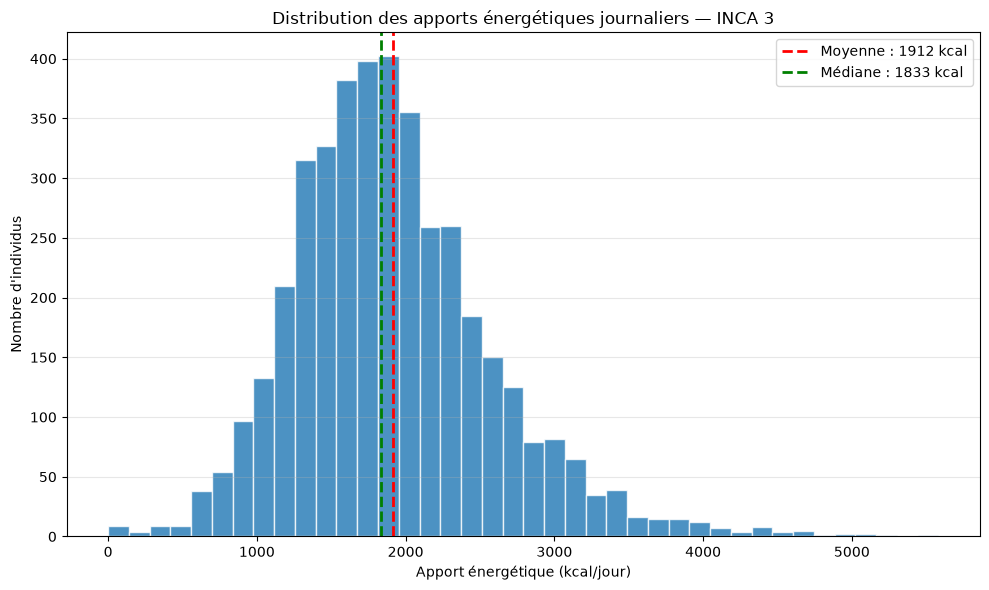

In [28]:
# Q1 : Visualisation de la distribution énergétique

import matplotlib.pyplot as plt

# Récupération des données à partir de la classe
df_energie = analyse.donnees_energie()

# Création de l'histogramme
plt.figure(figsize=(10, 6))

plt.hist(
    df_energie["energie_kcal"].dropna(),
    bins=40,
    edgecolor="white",
    alpha=0.8
)

# Ajout de la moyenne et de la médiane
moyenne = df_energie["energie_kcal"].mean()
mediane = df_energie["energie_kcal"].median()

plt.axvline(
    moyenne,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Moyenne : {moyenne:.0f} kcal"
)

plt.axvline(
    mediane,
    color="green",
    linestyle="--",
    linewidth=2,
    label=f"Médiane : {mediane:.0f} kcal"
)

# Mise en forme
plt.title("Distribution des apports énergétiques journaliers — INCA 3")
plt.xlabel("Apport énergétique (kcal/jour)")
plt.ylabel("Nombre d'individus")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

# Enregistrement du graphique pour le rapport final
dossier_figures = PROJECT_DIR / "reports" / "figures"
dossier_figures.mkdir(parents=True, exist_ok=True)

plt.savefig(
    dossier_figures / "q1_distribution_energie.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interprétation des résultats — Q1

L'analyse porte sur 4 114 individus disposant de données d'apports nutritionnels dans INCA 3.

L'apport énergétique journalier moyen est de 1 911,88 kcal, avec une médiane de 1 833,29 kcal et un écart-type de 672,88 kcal.

La moitié des participants présente un apport énergétique compris entre 1 461,34 et 2 275,14 kcal/jour.

La moyenne supérieure à la médiane suggère une asymétrie positive de la distribution, à examiner à l'aide de l'histogramme.

Huit individus présentent un apport énergétique nul. Ces observations sont conservées dans les statistiques descriptives générales et feront l'objet d'une attention particulière lors des calculs de densité nutritionnelle.

Les résultats présentés sont non pondérés et ne doivent pas être interprétés comme des estimations représentatives de l'ensemble de la population française.

In [29]:
# Identification des variables nutritionnelles disponibles

colonnes_nutriments = [
    colonne
    for colonne in dataframes["apports"].columns
    if colonne.startswith("nutriment")
]

print("Nombre de variables nutritionnelles :", len(colonnes_nutriments))
print("Variables disponibles :")
print(colonnes_nutriments)

Nombre de variables nutritionnelles : 54
Variables disponibles :
['nutriment1', 'nutriment2', 'nutriment3', 'nutriment4', 'nutriment5', 'nutriment6', 'nutriment7', 'nutriment8', 'nutriment9', 'nutriment10', 'nutriment11', 'nutriment12', 'nutriment13', 'nutriment14', 'nutriment15', 'nutriment16', 'nutriment17', 'nutriment18', 'nutriment19', 'nutriment20', 'nutriment21', 'nutriment22', 'nutriment23', 'nutriment24', 'nutriment25', 'nutriment26', 'nutriment27', 'nutriment28', 'nutriment29', 'nutriment30', 'nutriment31', 'nutriment32', 'nutriment33', 'nutriment34', 'nutriment35', 'nutriment36', 'nutriment37', 'nutriment38', 'nutriment39', 'nutriment40', 'nutriment41', 'nutriment42', 'nutriment43', 'nutriment44', 'nutriment45', 'nutriment46', 'nutriment47', 'nutriment48', 'nutriment49', 'nutriment50', 'nutriment51', 'nutriment52', 'nutriment53', 'nutriment54']


In [30]:
# Rechargement du module après modification du fichier Python
import importlib
import src.analyse_nutritionnelle

importlib.reload(src.analyse_nutritionnelle)

from src.analyse_nutritionnelle import AnalyseNutritionnelle

# Création d'une nouvelle instance
analyse = AnalyseNutritionnelle(DB_PATH)

# Q2 : Comparaison des apports selon le sexe
resultats_q2 = analyse.nutriments_par_sexe()

display(resultats_q2)

,sexe,nombre_individus,energie_moyenne_kcal,proteines_moyennes_g
0,1,1907,2119.51,81.40
1,2,2207,1732.47,67.32


## Q2 — Comparaison des apports nutritionnels selon le sexe

Cette analyse compare les apports énergétiques et protéiques moyens selon les modalités de sexe disponibles dans INCA 3.

Les résultats sont descriptifs et non pondérés. Les codes de sexe sont conservés en attendant leur vérification dans le dictionnaire officiel.

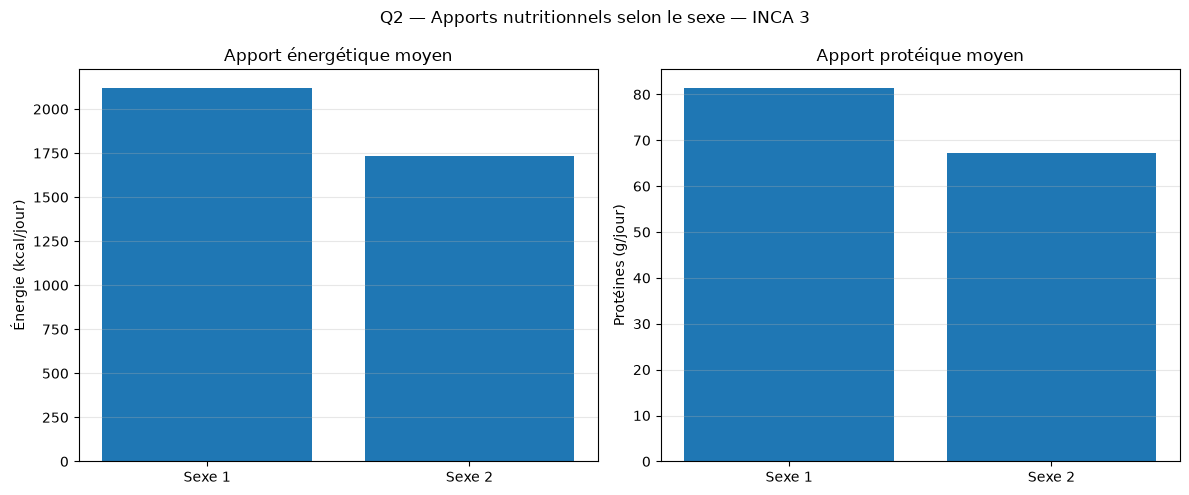

In [31]:
# Q2 : Comparaison des apports nutritionnels par sexe

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

etiquettes = [f"Sexe {s}" for s in resultats_q2["sexe"]]

# Comparaison des apports énergétiques
axes[0].bar(
    etiquettes,
    resultats_q2["energie_moyenne_kcal"]
)
axes[0].set_title("Apport énergétique moyen")
axes[0].set_ylabel("Énergie (kcal/jour)")
axes[0].grid(axis="y", alpha=0.3)

# Comparaison des apports protéiques
axes[1].bar(
    etiquettes,
    resultats_q2["proteines_moyennes_g"]
)
axes[1].set_title("Apport protéique moyen")
axes[1].set_ylabel("Protéines (g/jour)")
axes[1].grid(axis="y", alpha=0.3)

fig.suptitle("Q2 — Apports nutritionnels selon le sexe — INCA 3")

plt.tight_layout()

# Enregistrement de la figure
dossier_figures = PROJECT_DIR / "reports" / "figures"
dossier_figures.mkdir(parents=True, exist_ok=True)

plt.savefig(
    dossier_figures / "q2_nutriments_sexe.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interprétation — Q2

L'analyse porte sur 4 114 individus, répartis entre les modalités `sex_PS = 1` (1 907 individus) et `sex_PS = 2` (2 207 individus).

L'apport énergétique moyen est de 2 119,51 kcal/jour pour la première modalité, contre 1 732,47 kcal/jour pour la seconde.

L'apport protéique moyen est respectivement de 81,40 g/jour et de 67,32 g/jour.

Les différences observées sont descriptives. Les résultats ne sont pas pondérés et ne permettent pas, à ce stade, de conclure à une différence statistiquement significative.

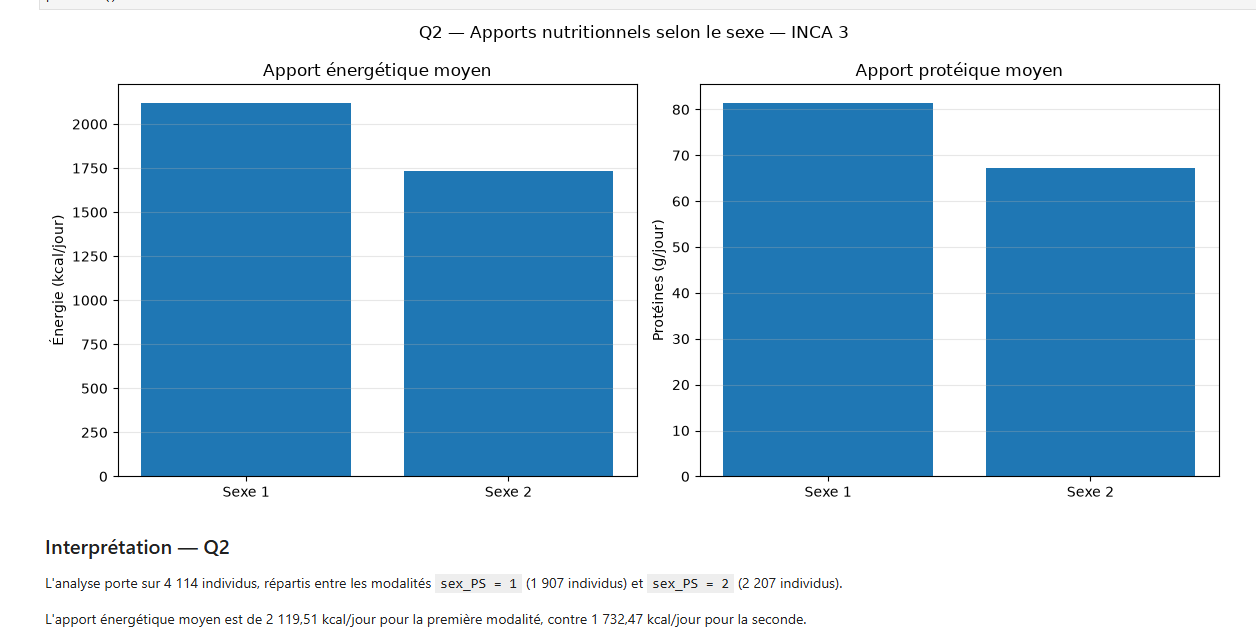

## Q3 — Apports nutritionnels selon les classes d'âge

Cette analyse examine les variations des apports énergétiques journaliers selon les neuf classes d'âge définies dans les données INCA 3.

Les codes `tage_PS` sont conservés en attendant la vérification des tranches d'âge correspondantes dans la documentation officielle.

Les résultats sont descriptifs et non pondérés.

,count,mean,median,std
tage_PS,,,,
1,59,573.60,632.28,335.04
2,159,1159.98,1130.58,290.73
3,345,1532.01,1491.77,364.75
4,481,1840.55,1814.85,399.72
5,543,1979.57,1911.13,545.62
6,406,1960.75,1869.31,666.92
7,783,2118.49,2046.85,731.88
8,827,2075.04,1949.73,719.07
9,511,1932.54,1881.74,665.03


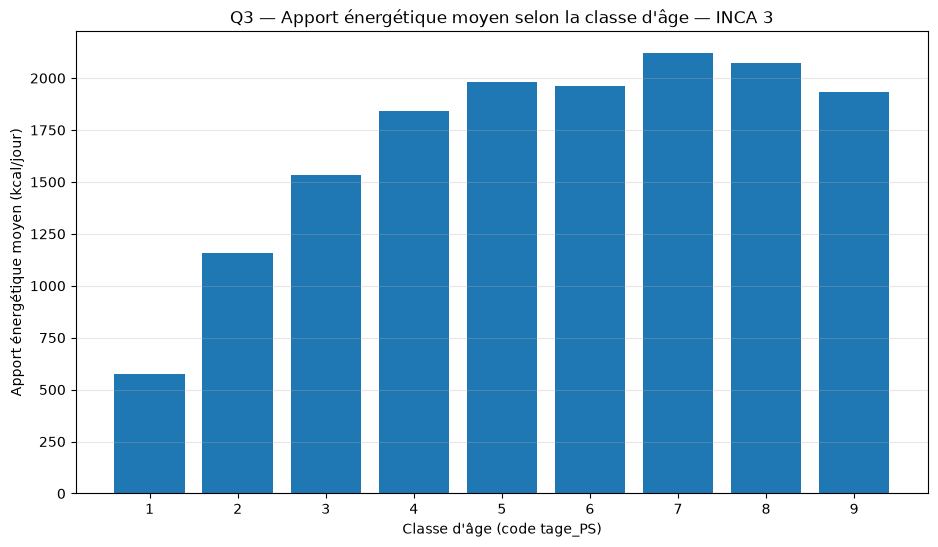

In [32]:
# Q3 : Comparaison des apports énergétiques selon l'âge

import matplotlib.pyplot as plt

# Récupération des statistiques par classe d'âge
resultats_q3 = analyse.energie_par_age()

display(resultats_q3)

# Création du graphique
plt.figure(figsize=(11, 6))

plt.bar(
    resultats_q3.index.astype(str),
    resultats_q3["mean"]
)

plt.title("Q3 — Apport énergétique moyen selon la classe d'âge — INCA 3")
plt.xlabel("Classe d'âge (code tage_PS)")
plt.ylabel("Apport énergétique moyen (kcal/jour)")
plt.grid(axis="y", alpha=0.3)

# Enregistrement du graphique
dossier_figures = PROJECT_DIR / "reports" / "figures"
dossier_figures.mkdir(parents=True, exist_ok=True)

plt.savefig(
    dossier_figures / "q3_energie_age.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interprétation des résultats — Q3

L'analyse des apports énergétiques selon les neuf classes d'âge met en évidence des différences importantes entre les groupes.

L'apport énergétique moyen passe de 573,60 kcal/jour pour la classe 1 à 1 979,57 kcal/jour pour la classe 5.

La valeur moyenne la plus élevée est observée dans la classe 7, avec 2 118,49 kcal/jour, tandis que la classe 9 présente une moyenne de 1 932,54 kcal/jour.

Ces variations doivent être interprétées en tenant compte des tranches d'âge correspondantes et des effectifs de chaque groupe.

Les résultats sont descriptifs et non pondérés.

In [33]:
# Dictionnaires de correspondance issus de la documentation INCA 3

codes_sexe = {
    1: "Homme",
    2: "Femme"
}

codes_age = {
    1: "0-11 mois",
    2: "1-3 ans",
    3: "4-6 ans",
    4: "7-10 ans",
    5: "11-14 ans",
    6: "15-17 ans",
    7: "18-44 ans",
    8: "45-64 ans",
    9: "65-79 ans"
}

# Création de variables descriptives
df_analyse["sexe"] = df_analyse["sex_PS"].map(codes_sexe)
df_analyse["classe_age"] = df_analyse["tage_PS"].map(codes_age)

# Vérification
display(df_analyse[
    ["NOIND", "sexe", "classe_age", "nutriment1", "nutriment3"]
].head(10))

,NOIND,sexe,classe_age,nutriment1,nutriment3
0,110100101,Homme,18-44 ans,2077.7625,83.054970
1,110100701,Femme,45-64 ans,1123.7395,42.008881
2,110100801,Homme,45-64 ans,2544.5754,87.255280
3,110101201,Homme,45-64 ans,2154.6367,64.621910
4,110101401,Femme,65-79 ans,1229.2993,44.161503
5,110300301,Homme,45-64 ans,2168.5913,77.496628
6,110300501,Homme,65-79 ans,1890.8549,78.354294
7,110600101,Femme,65-79 ans,1341.8519,66.752823
8,110601301,Femme,45-64 ans,2250.5129,82.319397
9,110602001,Femme,45-64 ans,1609.8219,57.142654


In [34]:
# Q4 - Calcul de la densité protéique pour 1000 kcal

df_densite = df_analyse.loc[
    df_analyse["nutriment1"] > 0
].copy()

df_densite["proteines_1000kcal"] = (
    df_densite["nutriment3"]
    / df_densite["nutriment1"]
    * 1000
)

# Statistiques descriptives par sexe
resultat_q4 = (
    df_densite
    .groupby("sexe")["proteines_1000kcal"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

display(resultat_q4)

,count,mean,median,std
sexe,,,,
Femme,2205,39.63,38.54,8.85
Homme,1901,38.84,37.99,8.56


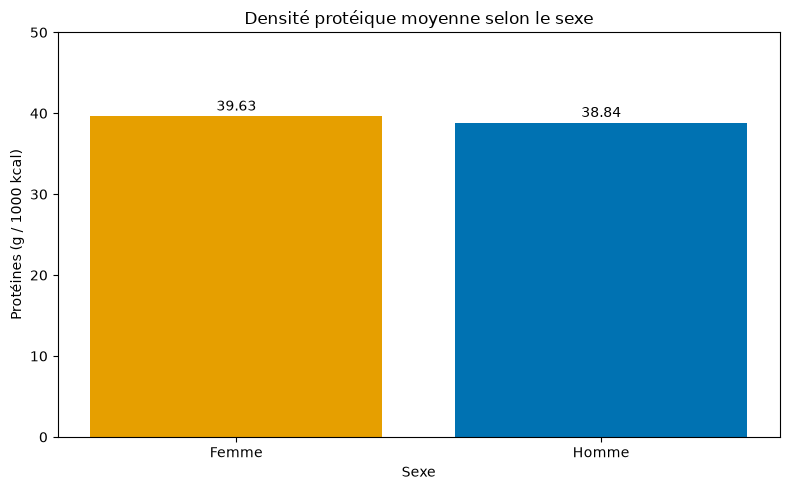

In [35]:
# Q4 - Visualisation de la densité protéique selon le sexe

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))

moyennes = resultat_q4["mean"]

ax.bar(
    moyennes.index,
    moyennes.values,
    color=["#E69F00", "#0072B2"]
)

ax.set_title("Densité protéique moyenne selon le sexe")
ax.set_xlabel("Sexe")
ax.set_ylabel("Protéines (g / 1000 kcal)")
ax.set_ylim(0, 50)

for i, valeur in enumerate(moyennes.values):
    ax.text(i, valeur + 0.7, f"{valeur:.2f}", ha="center")

plt.tight_layout()

# Enregistrement de la figure
dossier_figures = PROJECT_DIR / "reports" / "figures"
dossier_figures.mkdir(parents=True, exist_ok=True)

plt.savefig(
    dossier_figures / "q4_densite_proteique.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Q4 — Densité nutritionnelle : protéines pour 1 000 kcal

#### Objectif

L'objectif est de comparer les apports en protéines entre les hommes et les femmes, indépendamment de leur consommation énergétique totale.

#### Méthode

La densité protéique est calculée selon la formule suivante :

$$
\text{Densité protéique} =
\frac{\text{Apport en protéines (g/j)}}{\text{Apport énergétique (kcal/j)}} \times 1000
$$

Les individus présentant un apport énergétique nul ont été exclus de ce calcul afin d'éviter une division par zéro (8 individus).

#### Résultats

| Indicateur | Femmes | Hommes |
|---|---:|---:|
| Nombre d'individus | 2 205 | 1 901 |
| Moyenne (g/1 000 kcal) | 39,63 | 38,84 |
| Médiane (g/1 000 kcal) | 38,54 | 37,99 |
| Écart-type | 8,85 | 8,56 |

#### Interprétation

Les femmes présentent une densité protéique moyenne légèrement supérieure à celle des hommes (39,63 contre 38,84 g/1 000 kcal).

Bien que les hommes consomment davantage de protéines en quantité absolue, cette différence s'inverse lorsque les apports sont rapportés à l'énergie totale consommée.

La différence moyenne reste faible (0,79 g/1 000 kcal). Ces résultats sont descriptifs, non pondérés, et ne permettent pas de conclure à une différence statistiquement significative entre les sexes.

#### Conclusion

La densité nutritionnelle permet de comparer les apports en nutriments à énergie comparable. Elle complète l'analyse des apports absolus réalisée dans la question Q2.

In [36]:
# Q5 - Exploration des variables de consommation alimentaire

df_conso = dataframes["consommations"]

print("Dimensions :", df_conso.shape)

print("\nListe des colonnes :")
print(df_conso.columns.tolist())

print("\nAperçu des premières observations :")
display(df_conso.head(3))

Dimensions : (256301, 109)

Liste des colonnes :
['POPULATION', 'NOIND', 'NUM_LIGNE', 'R24_num', 'R24_nombre', 'R24_pond', 'occ_hdeb', 'occ_type', 'occ_lieu', 'occ_alim_libelle', 'occ_alim_num', 'occ_alim_num_seq', 'gpe_INCA3', 'aliment_code_INCA3', 'aliment_libelle_INCA3', 'aliment_code_FX', 'aliment_libelle_FX', 'qte_conso', 'qte_conso_pond', 'facette_01', 'facette_01_libelle', 'facette_02', 'facette_02_libelle', 'facette_03', 'facette_03_libelle', 'facette_04', 'facette_04_libelle', 'facette_05', 'facette_05_libelle', 'facette_06', 'facette_06_libelle', 'facette_07', 'facette_07_libelle', 'facette_08', 'facette_08_libelle', 'facette_09', 'facette_09_libelle', 'facette_10', 'facette_10_libelle', 'facette_12', 'facette_12_libelle', 'aliment_marque_bio', 'aliment_marque_enrichi', 'facette_13', 'facette_13_libelle', 'facette_14', 'facette_14_libelle', 'facette_19', 'facette_19_libelle', 'facette_20', 'facette_20_libelle', 'facette_25', 'facette_25_libelle', 'facette_27', 'facette_27_lib

,POPULATION,NOIND,NUM_LIGNE,R24_num,R24_nombre,R24_pond,occ_hdeb,occ_type,occ_lieu,occ_alim_libelle,...,magnesium,phosphore,potassium,calcium,manganese,fer,cuivre,zinc,selenium,iode
0,Pop3,110100101,3,1,3,1.0,11:00,4,1,eau,...,0.99,0.0,0.73,7.13,0.00082,0.030,0.017,0.011,0.5,0.0
1,Pop3,110100101,16,1,3,1.0,12:30,5,1,jus d orange,...,9.85,16.2,170.00,0.41,0.02300,0.068,0.025,0.045,1.1,0.7
2,Pop3,110100101,800001,1,3,1.0,12:30,5,1,poulet,...,0.00,0.0,0.00,0.00,0.00000,0.000,0.000,0.000,0.0,0.0


In [37]:
# Q5 - Vérification des quantités consommées et des valeurs nutritionnelles

colonnes_q5 = [
    "aliment_libelle_INCA3",
    "qte_conso",
    "proteines",
    "calcium",
    "fer",
    "fibres",
    "vitamine_c"
]

# Sélection de quelques aliments courants
exemples = df_conso[
    df_conso["aliment_libelle_INCA3"]
    .str.contains(
        "poulet|lait|pain|orange",
        case=False,
        na=False
    )
]

display(exemples[colonnes_q5].head(15))

,aliment_libelle_INCA3,qte_conso,proteines,calcium,fer,fibres,vitamine_c
4,nugget de poulet,161.000000,12.00,11.0,1.210,0.00,0.750
12,pain blanc,29.400000,7.98,23.2,1.320,2.92,0.600
16,lait (classique),249.599990,3.29,117.0,0.045,0.00,1.500
22,pain blanc,46.199997,8.55,20.0,1.060,2.69,2.500
33,pain blanc,31.499998,7.98,23.2,1.320,2.92,0.600
41,cuisse de poulet,149.184010,24.80,11.6,1.200,0.00,0.000
44,pain blanc,75.599998,8.55,20.0,1.060,2.69,2.500
70,chocolat en tablette au lait,14.000000,7.41,227.0,1.220,2.46,0.058
130,pain blanc,44.099998,7.98,23.2,1.320,2.92,0.600
134,cuisse de poulet,138.600010,25.90,14.6,1.200,0.00,3.000


In [38]:
# Q5 - Calcul des apports nutritionnels par consommation

nutriments_q5 = [
    "proteines",
    "calcium",
    "fer",
    "fibres",
    "vitamine_c"
]

# Création d'une copie pour conserver les données originales
df_q5 = df_conso.copy()

# Calcul des apports à partir des teneurs pour 100 g
for nutriment in nutriments_q5:
    df_q5[f"apport_{nutriment}"] = (
        df_q5["qte_conso"] * df_q5[nutriment] / 100
    )

# Vérification sur quelques observations
colonnes_resultat = [
    "aliment_libelle_INCA3",
    "qte_conso",
    "apport_proteines",
    "apport_calcium",
    "apport_fer",
    "apport_fibres",
    "apport_vitamine_c"
]

display(df_q5[colonnes_resultat].head(10))

,aliment_libelle_INCA3,qte_conso,apport_proteines,apport_calcium,apport_fer,apport_fibres,apport_vitamine_c
0,eau (du robinet),147.50000,0.000000,10.516750,0.044250,0.000000,0.000000
1,jus de fruits 100% pur jus,500.00000,3.050000,2.050000,0.340000,1.400000,123.500000
2,matière grasse de cuisson n.s.,3.22000,0.000000,0.000000,0.000000,0.000000,0.000000
3,frite (de pommes de terre) à la friteuse,107.00000,3.509600,25.466000,0.963000,4.173000,20.330000
4,nugget de poulet,161.00000,19.320000,17.710000,1.948100,0.000000,1.207500
5,matière grasse n.s.,12.84000,0.000000,0.000000,0.000000,0.000000,0.000000
6,hamburger,106.00000,15.508818,61.977061,1.625333,2.044542,0.157623
7,chewing gum,1.40000,0.005320,0.000000,0.070000,0.033600,0.000000
8,eau au sirop type menthe à l'eau,446.92499,0.245809,33.742837,0.111731,0.000000,5.810025
9,yaourt avec fruits brassé type velouté fruix,125.00000,3.712500,137.500000,0.056250,0.262500,0.500000


In [40]:
# Q5 - Calcul des contributions nutritionnelles pondérées

for nutriment in nutriments_q5:
    df_q5[f"apport_pond_{nutriment}"] = (
        df_q5[f"apport_{nutriment}"] * df_q5["R24_pond"]
    )

# Regroupement par aliment
colonnes_apports = [
    f"apport_pond_{nutriment}"
    for nutriment in nutriments_q5
]

contributions_aliments = (
    df_q5
    .groupby(
        ["aliment_code_INCA3", "aliment_libelle_INCA3"],
        as_index=False
    )[colonnes_apports]
    .sum()
)

# Calcul de la contribution relative de chaque aliment
for nutriment in nutriments_q5:
    colonne = f"apport_pond_{nutriment}"
    total = contributions_aliments[colonne].sum()

    contributions_aliments[f"pct_{nutriment}"] = (
        contributions_aliments[colonne] / total * 100
    )

# Affichage des dix principaux contributeurs en protéines
top10_proteines = contributions_aliments.nlargest(
    10, "apport_pond_proteines"
)

display(
    top10_proteines[
        ["aliment_libelle_INCA3", "pct_proteines"]
    ].round(2)
)

,aliment_libelle_INCA3,pct_proteines
346,pain blanc,7.10
173,lait (classique),3.33
1483,chocolat chaud à base de lait,3.03
497,escalope de poulet,2.52
428,bifteck de boeuf,2.41
433,viande hachée de boeuf,2.39
495,cuisse de poulet,2.07
1847,pâte alimentaire (classique),1.65
2333,pizza,1.36
2224,jambon cuit sans couenne,1.20



Top 10 - Protéines


,aliment_libelle_INCA3,pct_proteines
346,pain blanc,7.10
173,lait (classique),3.33
1483,chocolat chaud à base de lait,3.03
497,escalope de poulet,2.52
428,bifteck de boeuf,2.41
433,viande hachée de boeuf,2.39
495,cuisse de poulet,2.07
1847,pâte alimentaire (classique),1.65
2333,pizza,1.36
2224,jambon cuit sans couenne,1.20


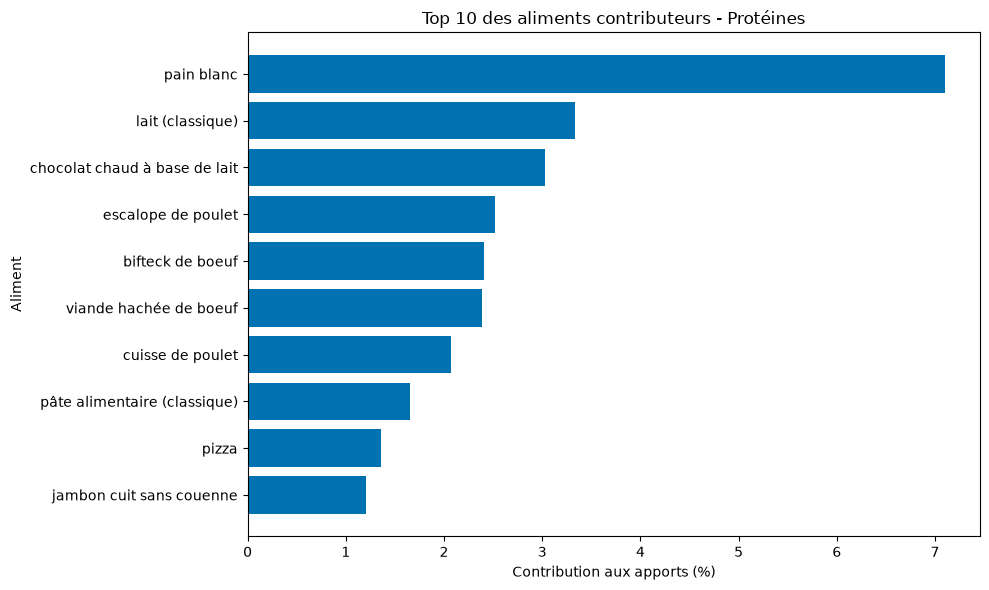


Top 10 - Calcium


,aliment_libelle_INCA3,pct_calcium
173,lait (classique),9.63
1483,chocolat chaud à base de lait,8.30
886,eau (du robinet),3.36
177,yaourt nature,2.72
884,eau minérale plate non aromatisée,2.48
249,comté,2.02
2333,pizza,1.93
1573,eau de source plate non aromatisée,1.89
346,pain blanc,1.70
2179,yaourt aromatisé,1.61


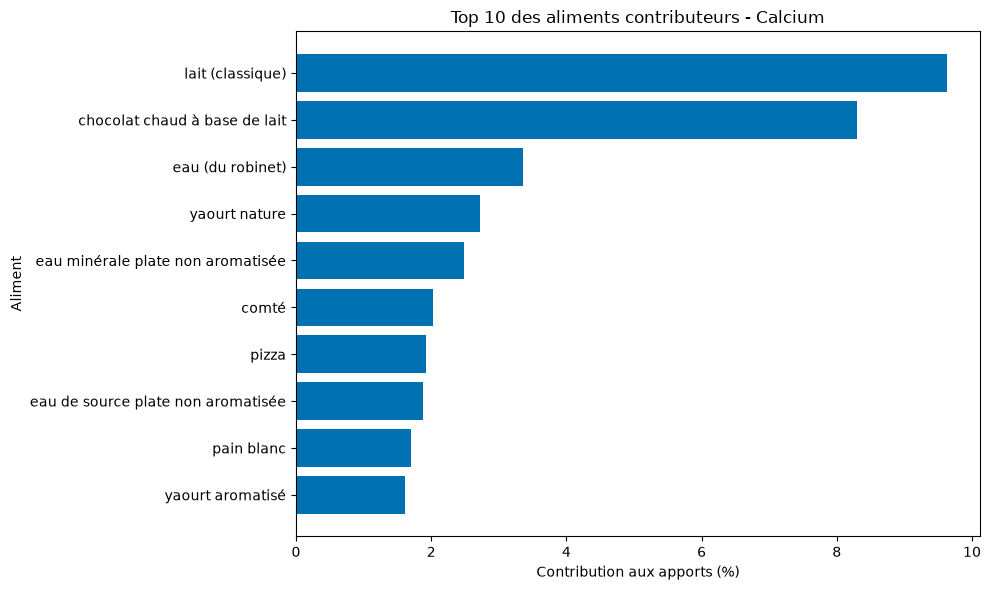


Top 10 - Fer


,aliment_libelle_INCA3,pct_fer
346,pain blanc,8.39
1483,chocolat chaud à base de lait,3.27
433,viande hachée de boeuf,2.02
2033,soupe (de légumes),1.54
428,bifteck de boeuf,1.52
714,pâte à tartiner chocolat noisette type nutella,1.41
1847,pâte alimentaire (classique),1.36
886,eau (du robinet),1.32
891,vin rouge,1.18
526,boudin noir,1.13


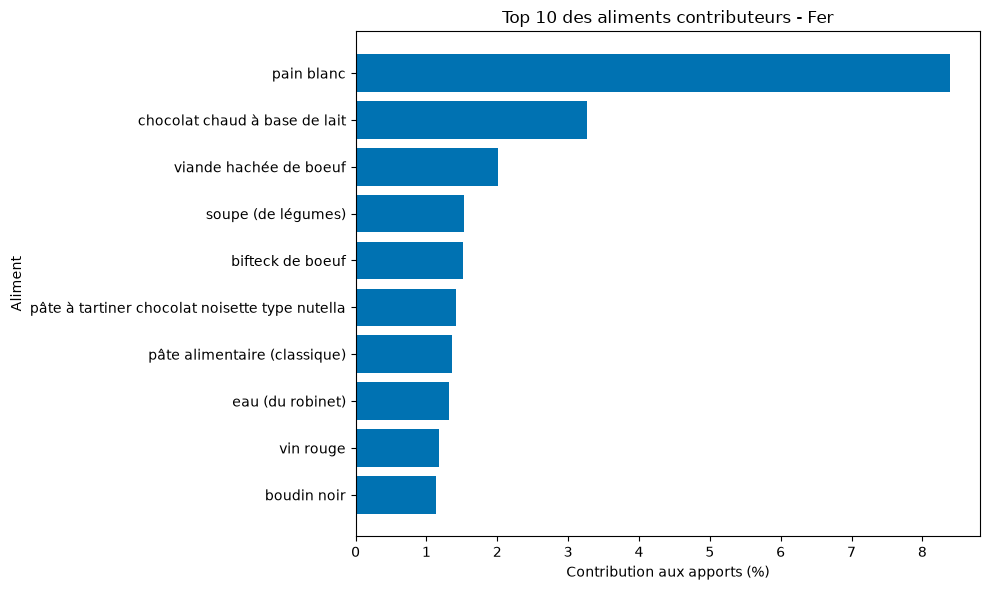


Top 10 - Fibres


,aliment_libelle_INCA3,pct_fibres
346,pain blanc,10.77
1847,pâte alimentaire (classique),3.27
2033,soupe (de légumes),3.07
33,haricot vert,2.35
1504,compote (de fruits),2.26
2151,frite (de pommes de terre) à la friteuse,2.11
0,pomme de terre,2.07
1483,chocolat chaud à base de lait,1.60
353,pain complet,1.38
352,pain aux céréales,1.35


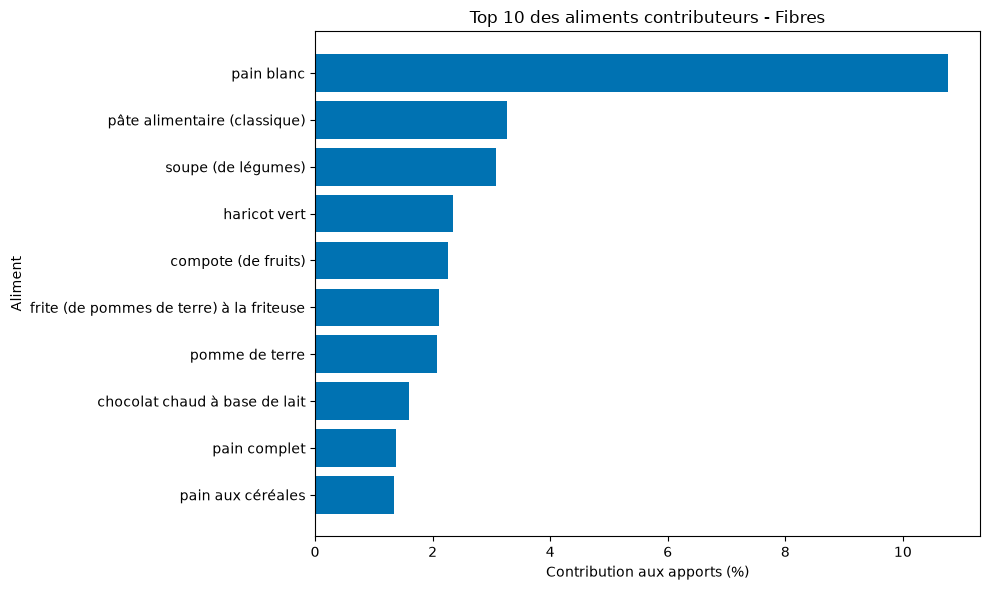


Top 10 - Vitamine C


,aliment_libelle_INCA3,pct_vitamine_c
1665,jus de fruits 100% pur jus,15.71
132,orange (classique),6.61
116,fraise,4.57
1666,jus de fruits à base de concentré,4.09
122,kiwi (frais),3.83
1504,compote (de fruits),3.70
2033,soupe (de légumes),3.59
40,tomate rouge,3.29
143,mandarine,2.86
1937,ratatouille,2.28


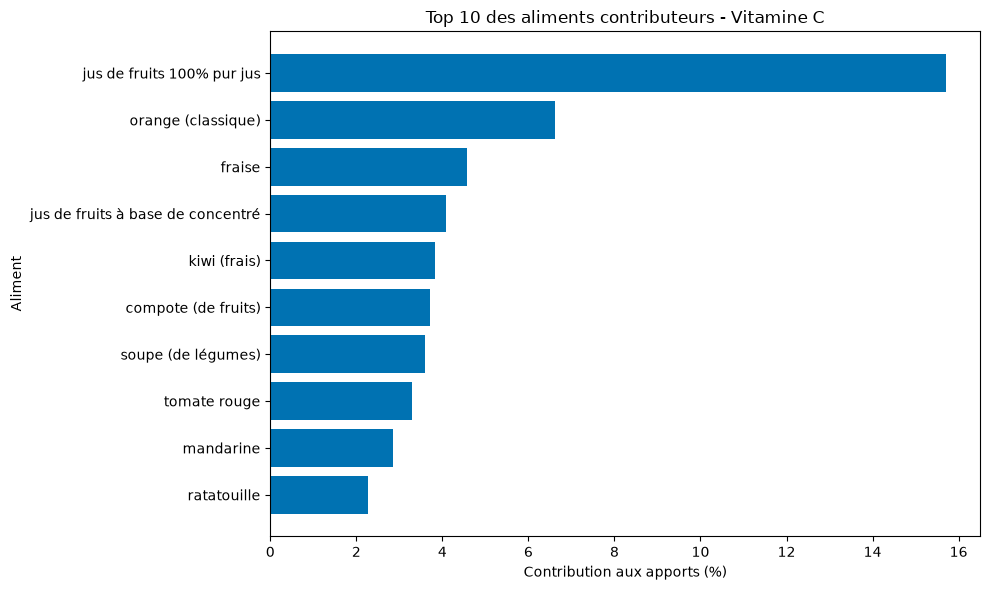

In [41]:
# Q5 - Visualisation des dix principaux aliments contributeurs

import matplotlib.pyplot as plt

noms_nutriments = {
    "proteines": "Protéines",
    "calcium": "Calcium",
    "fer": "Fer",
    "fibres": "Fibres",
    "vitamine_c": "Vitamine C"
}

resultats_q5 = {}

for nutriment, nom in noms_nutriments.items():

    # Sélection des dix principaux contributeurs
    top10 = contributions_aliments.nlargest(
        10, f"pct_{nutriment}"
    ).copy()

    resultats_q5[nutriment] = top10

    # Affichage du tableau
    print(f"\nTop 10 - {nom}")

    display(
        top10[
            ["aliment_libelle_INCA3", f"pct_{nutriment}"]
        ].round(2)
    )

    # Création du graphique
    top10_graphique = top10.sort_values(
        f"pct_{nutriment}"
    )

    fig, ax = plt.subplots(figsize=(10, 6))

    ax.barh(
        top10_graphique["aliment_libelle_INCA3"],
        top10_graphique[f"pct_{nutriment}"],
        color="#0072B2"
    )

    ax.set_title(
        f"Top 10 des aliments contributeurs - {nom}"
    )
    ax.set_xlabel("Contribution aux apports (%)")
    ax.set_ylabel("Aliment")

    plt.tight_layout()

    # Enregistrement de la figure
    dossier_figures.mkdir(parents=True, exist_ok=True)

    plt.savefig(
        dossier_figures / f"q5_top10_{nutriment}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

### Q5 — Principaux aliments contributeurs aux apports nutritionnels

#### Objectif

Identifier les aliments qui contribuent le plus aux apports en protéines, calcium, fer, fibres et vitamine C dans les données de consommation alimentaire INCA 3.

#### Méthode

Pour chaque consommation alimentaire, l'apport nutritionnel a été calculé à partir de la quantité consommée et de la teneur du nutriment pour 100 g d'aliment :

$$
\text{Apport nutritionnel} =
\frac{\text{Quantité consommée (g)} \times
\text{Teneur nutritionnelle (pour 100 g)}}{100}
$$

Les apports ont ensuite été multipliés par le coefficient `R24_pond`, puis regroupés par code et libellé d'aliment.

La contribution relative de chaque aliment a été calculée selon :

$$
\text{Contribution (\%)} =
\frac{\text{Apport pondéré de l'aliment}}
{\text{Apport pondéré total du nutriment}}
\times 100
$$

Les dix principaux aliments contributeurs ont été identifiés pour chaque nutriment.

#### Résultats

| Nutriment | Premier aliment contributeur | Contribution |
|---|---|---:|
| Protéines | Pain blanc | 7,10 % |
| Calcium | Lait (classique) | 9,63 % |
| Fer | Pain blanc | 8,39 % |
| Fibres | Pain blanc | 10,77 % |
| Vitamine C | Jus de fruits 100 % pur jus | 15,71 % |

#### Interprétation

**Protéines :** Le pain blanc constitue le premier contributeur (7,10 %), devant le lait classique (3,33 %) et le chocolat chaud à base de lait (3,03 %). Ce résultat souligne l'importance des quantités et des fréquences de consommation.

**Calcium :** Les produits laitiers occupent une place importante, notamment le lait classique (9,63 %) et le chocolat chaud à base de lait (8,30 %). Certaines eaux contribuent également aux apports en calcium.

**Fer :** Le pain blanc représente 8,39 % des apports calculés, suivi du chocolat chaud à base de lait (3,27 %) et de la viande hachée de bœuf (2,02 %).

**Fibres :** Le pain blanc représente 10,77 % des apports, suivi des pâtes alimentaires (3,27 %) et des soupes de légumes (3,07 %).

**Vitamine C :** Les jus de fruits 100 % pur jus constituent le premier contributeur (15,71 %), suivis des oranges (6,61 %) et des fraises (4,57 %).

#### Limites méthodologiques

Les contributions sont calculées à partir des consommations observées et du coefficient `R24_pond`. Elles ne constituent pas, à ce stade, des estimations représentatives de l'ensemble de la population française, car les poids d'enquête individuels n'ont pas été appliqués.

La signification exacte du coefficient `R24_pond` doit être confirmée dans la documentation avant la finalisation du rapport.

#### Conclusion

Les principaux contributeurs nutritionnels ne sont pas nécessairement les aliments présentant les concentrations les plus élevées en nutriments. Leur contribution dépend également des quantités consommées et de leur fréquence de consommation.

In [42]:
# Q6 - Sélection du sous-groupe des femmes de 18 à 44 ans

df_q6 = df_analyse[
    (df_analyse["sex_PS"] == 2) &
    (df_analyse["tage_PS"] == 7)
].copy()

print("Nombre de femmes âgées de 18 à 44 ans :", len(df_q6))

# Analyse de la variabilité des apports énergétiques et protéiques
statistiques_q6 = df_q6[
    ["nutriment1", "nutriment3"]
].describe().round(2)

statistiques_q6 = statistiques_q6.rename(
    columns={
        "nutriment1": "Énergie (kcal/j)",
        "nutriment3": "Protéines (g/j)"
    }
)

display(statistiques_q6)

Nombre de femmes âgées de 18 à 44 ans : 459


,Énergie (kcal/j),Protéines (g/j)
count,459.00,459.00
mean,1881.47,70.90
std,597.74,22.48
min,323.15,14.26
25%,1477.77,56.59
50%,1826.95,67.89
75%,2240.80,83.83
max,5582.39,194.15


,Nutriment,Effectif,Moyenne,Écart-type,CV (%),P10,Médiane,P90
0,Énergie (kcal/j),459,1881.47,597.74,31.77,1208.38,1826.95,2683.68
1,Protéines (g/j),459,70.90,22.48,31.71,45.52,67.89,98.77


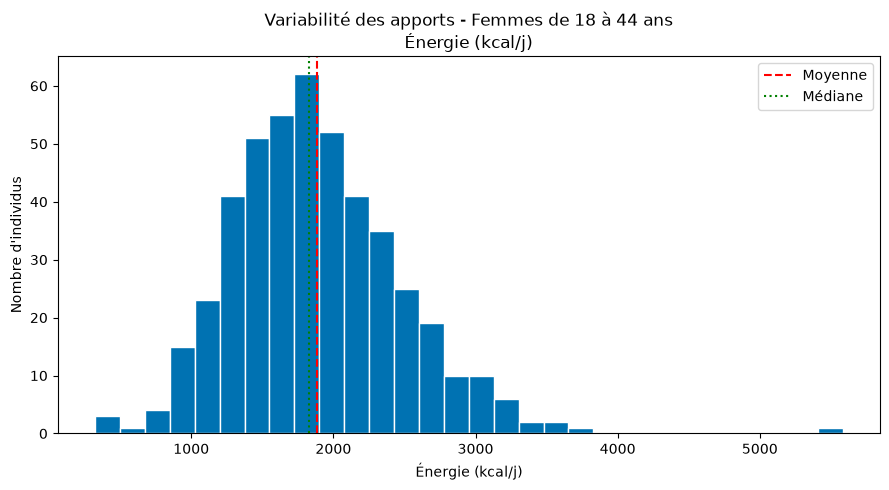

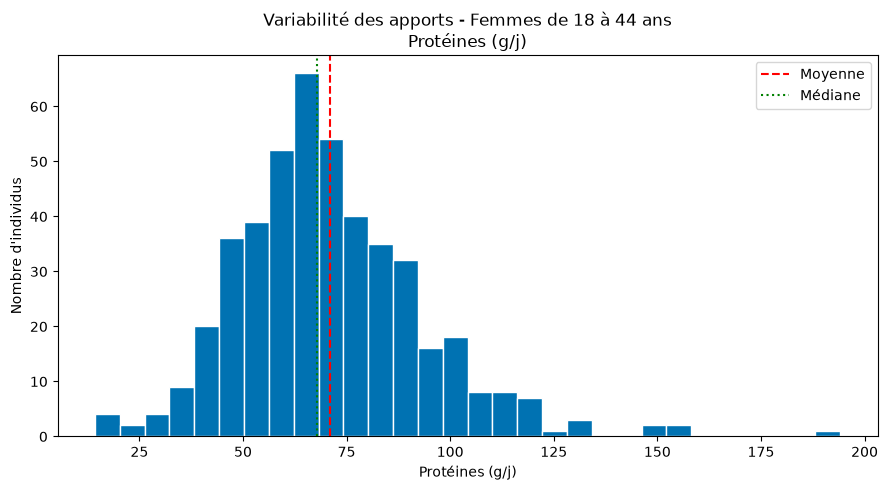

In [43]:
# Q6 - Analyse de la variabilité des apports nutritionnels

import matplotlib.pyplot as plt

variables_q6 = {
    "nutriment1": "Énergie (kcal/j)",
    "nutriment3": "Protéines (g/j)"
}

resultats_variabilite = []

for colonne, nom in variables_q6.items():
    serie = df_q6[colonne].dropna()

    moyenne = serie.mean()
    ecart_type = serie.std()

    resultats_variabilite.append({
        "Nutriment": nom,
        "Effectif": len(serie),
        "Moyenne": moyenne,
        "Écart-type": ecart_type,
        "CV (%)": ecart_type / moyenne * 100,
        "P10": serie.quantile(0.10),
        "Médiane": serie.median(),
        "P90": serie.quantile(0.90)
    })

df_variabilite = pd.DataFrame(resultats_variabilite)

display(df_variabilite.round(2))

# Création et enregistrement des histogrammes
for colonne, nom in variables_q6.items():

    fig, ax = plt.subplots(figsize=(9, 5))

    ax.hist(
        df_q6[colonne].dropna(),
        bins=30,
        color="#0072B2",
        edgecolor="white"
    )

    ax.axvline(
        df_q6[colonne].mean(),
        color="red",
        linestyle="--",
        label="Moyenne"
    )

    ax.axvline(
        df_q6[colonne].median(),
        color="green",
        linestyle=":",
        label="Médiane"
    )

    ax.set_title(
        f"Variabilité des apports - Femmes de 18 à 44 ans\n{nom}"
    )
    ax.set_xlabel(nom)
    ax.set_ylabel("Nombre d'individus")
    ax.legend()

    plt.tight_layout()

    nom_fichier = (
        "q6_variabilite_energie.png"
        if colonne == "nutriment1"
        else "q6_variabilite_proteines.png"
    )

    plt.savefig(
        dossier_figures / nom_fichier,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

### Q6 — Variabilité des apports nutritionnels dans un sous-groupe

#### Objectif

Étudier la variabilité des apports énergétiques et protéiques au sein d'un sous-groupe homogène de la population INCA 3.

Le sous-groupe sélectionné correspond aux femmes âgées de 18 à 44 ans.

#### Méthode

Les individus ont été sélectionnés à partir des variables `sex_PS = 2` et `tage_PS = 7`.

Les indicateurs statistiques utilisés sont la moyenne, la médiane, l'écart-type, les percentiles et le coefficient de variation.

Le coefficient de variation est calculé selon :

$$
CV = \frac{\text{Écart-type}}{\text{Moyenne}} \times 100
$$

Cet indicateur permet de comparer la variabilité relative de plusieurs variables exprimées dans des unités différentes.

#### Résultats

L'analyse porte sur 459 femmes âgées de 18 à 44 ans.

| Indicateur | Énergie (kcal/j) | Protéines (g/j) |
|---|---:|---:|
| Moyenne | 1 881,47 | 70,90 |
| Médiane | 1 826,95 | 67,89 |
| Écart-type | 597,74 | 22,48 |
| Minimum | 323,15 | 14,26 |
| Maximum | 5 582,39 | 194,15 |
| Coefficient de variation | 31,77 % | 31,71 % |

#### Analyse des percentiles et des distributions

Les percentiles P10 et P90 montrent que 80 % des femmes âgées de 18 à 44 ans présentent des apports énergétiques compris approximativement entre 1 208 et 2 684 kcal/j, et des apports protéiques compris entre 45,52 et 98,77 g/j.

Les histogrammes montrent des distributions unimodales avec une asymétrie vers les valeurs élevées. Quelques observations extrêmes sont présentes, notamment pour les apports énergétiques.

Les coefficients de variation sont très proches : 31,77 % pour l'énergie et 31,71 % pour les protéines, indiquant une variabilité relative comparable.

#### Interprétation

Les apports énergétiques et protéiques présentent une variabilité importante au sein du sous-groupe étudié.

Les coefficients de variation sont proches de 32 % pour les deux variables, indiquant une dispersion relative similaire.

Les moyennes sont légèrement supérieures aux médianes, ce qui suggère une asymétrie positive des distributions.

Les valeurs extrêmes observées peuvent influencer les statistiques descriptives. Elles nécessiteraient une analyse complémentaire avant toute interprétation nutritionnelle individuelle.

#### Conclusion

Même au sein d'un sous-groupe défini par le sexe et la classe d'âge, les apports nutritionnels présentent une hétérogénéité notable.

Cette analyse souligne l'intérêt de compléter les moyennes par des indicateurs de dispersion et de position.